In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

In [3]:
# Choose the used-cars CSV file from your computer
from google.colab import files

uploaded = files.upload()
csv_file = next(iter(uploaded))
df = pd.read_csv(csv_file)

print('Shape:', df.shape)
df.head()

Saving archive (8).zip to archive (8).zip
Shape: (4269, 13)


,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   loan_id                    4269 non-null   int64 
 1   no_of_dependents           4269 non-null   int64 
 2    education                 4269 non-null   object
 3    self_employed             4269 non-null   object
 4    income_annum              4269 non-null   int64 
 5    loan_amount               4269 non-null   int64 
 6    loan_term                 4269 non-null   int64 
 7    cibil_score               4269 non-null   int64 
 8    residential_assets_value  4269 non-null   int64 
 9    commercial_assets_value   4269 non-null   int64 
 10   luxury_assets_value       4269 non-null   int64 
 11   bank_asset_value          4269 non-null   int64 
 12   loan_status               4269 non-null   object
dtypes: int64(10), object(3)
memory usage: 433.7+ KB


In [5]:
df.isnull().sum()

,0
loan_id,0
no_of_dependents,0
education,0
self_employed,0
income_annum,0
loan_amount,0
loan_term,0
cibil_score,0
residential_assets_value,0
commercial_assets_value,0


In [6]:
df.duplicated().sum()

np.int64(0)

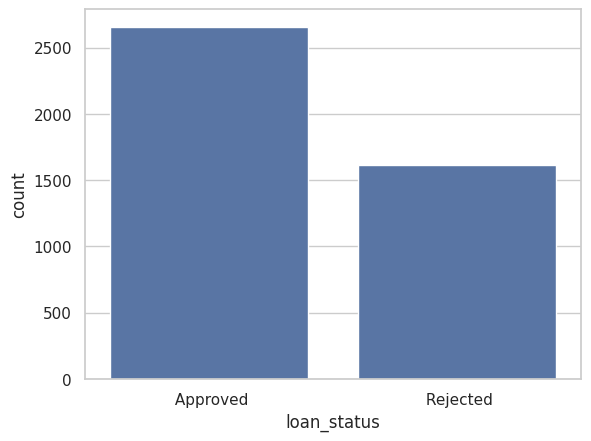

In [13]:
# Clean column names by stripping leading/trailing whitespace
df.columns = df.columns.str.strip()

# Univariate Analysis
sns.countplot(x='loan_status', data=df)
plt.show()

In [14]:
# Check the target class distribution
print(df["loan_status"].value_counts())

# Check percentages
print(df["loan_status"].value_counts(normalize=True) * 100)

loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64
loan_status
Approved    62.215976
Rejected    37.784024
Name: proportion, dtype: float64


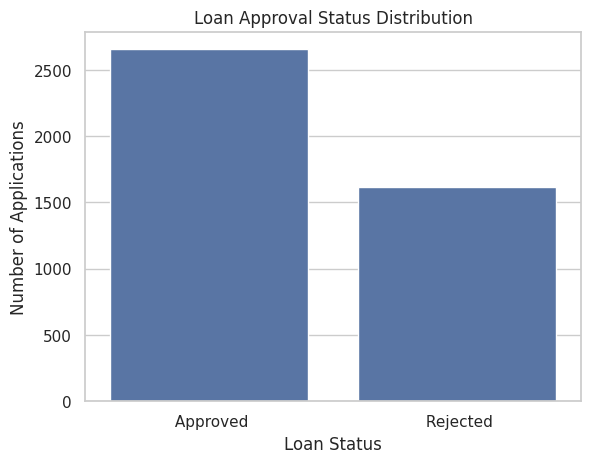

In [15]:
sns.countplot(x="loan_status", data=df)
plt.title("Loan Approval Status Distribution")
plt.xlabel("Loan Status")
plt.ylabel("Number of Applications")
plt.show()

In [16]:
# Select numerical columns
numeric_cols = df.select_dtypes(include=["int64", "float64"]).columns

# Display descriptive statistics
print(df[numeric_cols].describe())

           loan_id  no_of_dependents  income_annum   loan_amount    loan_term  \
count  4269.000000       4269.000000  4.269000e+03  4.269000e+03  4269.000000   
mean   2135.000000          2.498712  5.059124e+06  1.513345e+07    10.900445   
std    1232.498479          1.695910  2.806840e+06  9.043363e+06     5.709187   
min       1.000000          0.000000  2.000000e+05  3.000000e+05     2.000000   
25%    1068.000000          1.000000  2.700000e+06  7.700000e+06     6.000000   
50%    2135.000000          3.000000  5.100000e+06  1.450000e+07    10.000000   
75%    3202.000000          4.000000  7.500000e+06  2.150000e+07    16.000000   
max    4269.000000          5.000000  9.900000e+06  3.950000e+07    20.000000   

       cibil_score  residential_assets_value  commercial_assets_value  \
count  4269.000000              4.269000e+03             4.269000e+03   
mean    599.936051              7.472617e+06             4.973155e+06   
std     172.430401              6.503637e+06       

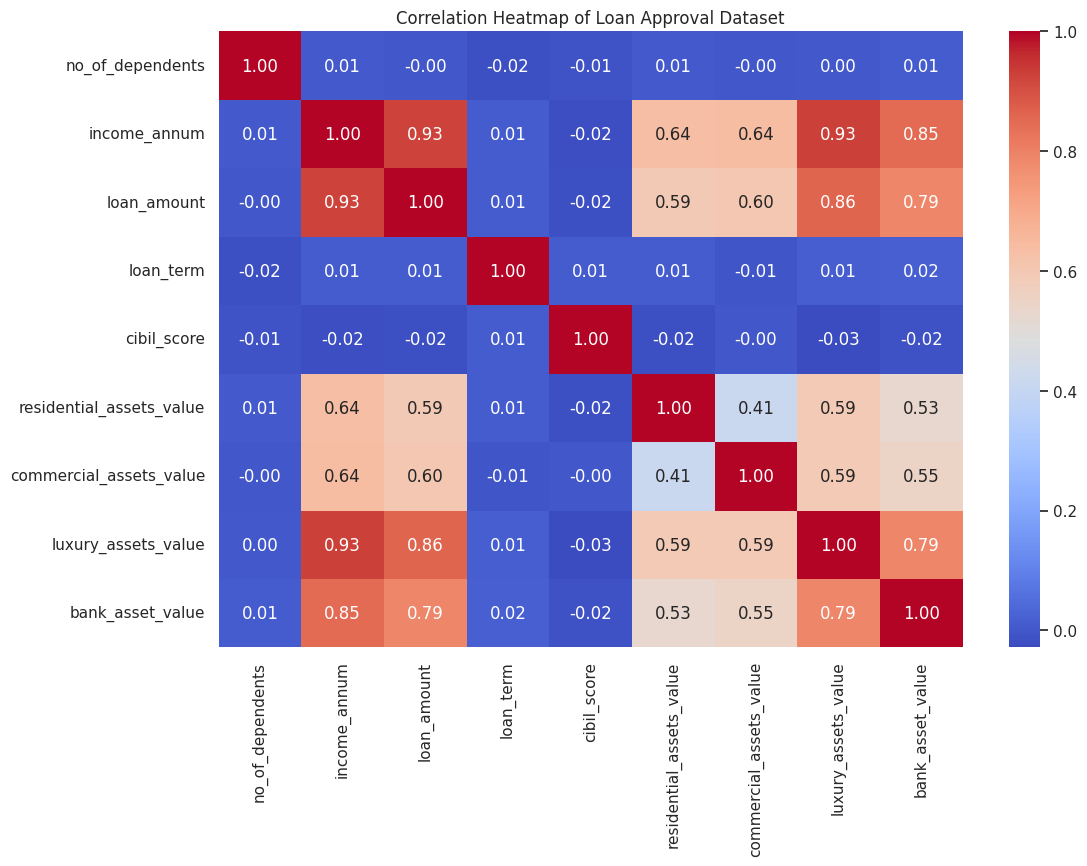

In [17]:
# Select numerical columns, excluding the ID
numeric_df = df.select_dtypes(include=["int64", "float64"])
numeric_df = numeric_df.drop(columns=["loan_id"], errors="ignore")

# Create the correlation matrix
correlation_matrix = numeric_df.corr()

# Plot the heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap of Loan Approval Dataset")
plt.show()

In [18]:
print("Categorical columns:")
print(df.select_dtypes(include=["object", "category"]).columns.tolist())

Categorical columns:
['education', 'self_employed', 'loan_status']


In [21]:
# Separate input features and target
X = df.drop(columns=["loan_status", "loan_id"])
y = df["loan_status"].map({
    "Approved": 1,
    "Rejected": 0})

In [22]:
# Encode categorical input features
X = pd.get_dummies(
    X,
    columns=["education", "self_employed"],
    drop_first=True,
    dtype=int
)

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget values:")
print(y.value_counts())

Features shape: (4269, 11)
Target shape: (4269,)

Target values:
Series([], Name: count, dtype: int64)


In [24]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   loan_id                   4269 non-null   int64 
 1   no_of_dependents          4269 non-null   int64 
 2   education                 4269 non-null   object
 3   self_employed             4269 non-null   object
 4   income_annum              4269 non-null   int64 
 5   loan_amount               4269 non-null   int64 
 6   loan_term                 4269 non-null   int64 
 7   cibil_score               4269 non-null   int64 
 8   residential_assets_value  4269 non-null   int64 
 9   commercial_assets_value   4269 non-null   int64 
 10  luxury_assets_value       4269 non-null   int64 
 11  bank_asset_value          4269 non-null   int64 
 12  loan_status               4269 non-null   object
dtypes: int64(10), object(3)
memory usage: 433.7+ KB


In [25]:
print(df["loan_status"].unique())
print(df["loan_status"].value_counts(dropna=False))

[' Approved' ' Rejected']
loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64


In [26]:
# Remove leading and trailing spaces
df["loan_status"] = df["loan_status"].str.strip()

# Encode the target variable
y = df["loan_status"].map({
    "Approved": 1,
    "Rejected": 0
})

# Verify the result
print(y.value_counts())
print("Missing target values:", y.isna().sum())

loan_status
1    2656
0    1613
Name: count, dtype: int64
Missing target values: 0


In [27]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

Training features: (3415, 11)
Testing features: (854, 11)


In [29]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train, y_train
)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

Before SMOTE:
loan_status
1    2125
0    1290
Name: count, dtype: int64

After SMOTE:
loan_status
1    2125
0    2125
Name: count, dtype: int64


In [31]:
from sklearn.ensemble import RandomForestClassifier

In [32]:
model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42
)

model.fit(X_train_smote, y_train_smote)

print("Model trained successfully!")

Model trained successfully!


In [33]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Predict test outcomes
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.9789
Precision: 0.9849
Recall: 0.9812
F1-score: 0.983
ROC-AUC: 0.9986

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.98      0.97       323
           1       0.98      0.98      0.98       531

    accuracy                           0.98       854
   macro avg       0.98      0.98      0.98       854
weighted avg       0.98      0.98      0.98       854



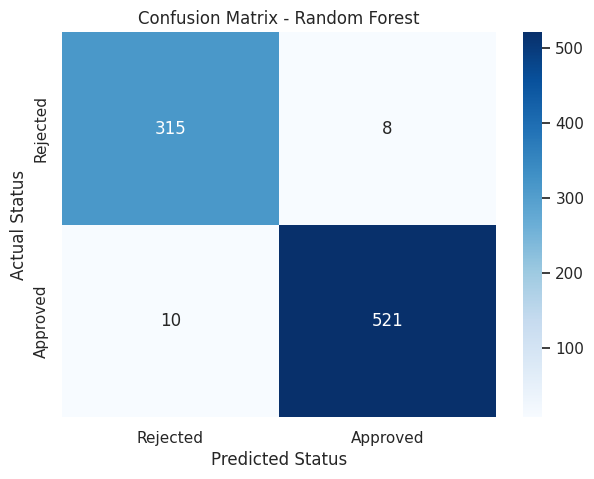

[[315   8]
 [ 10 521]]


In [34]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Rejected", "Approved"],
    yticklabels=["Rejected", "Approved"]
)

plt.xlabel("Predicted Status")
plt.ylabel("Actual Status")
plt.title("Confusion Matrix - Random Forest")
plt.show()

print(cm)

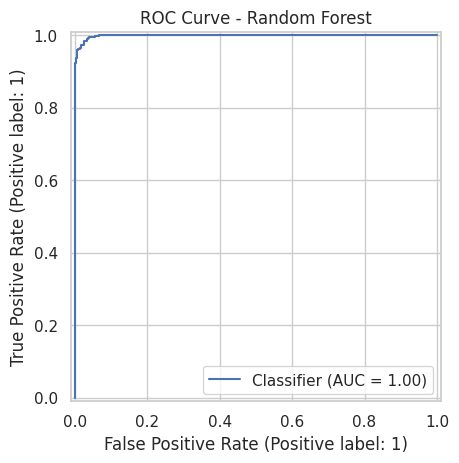

In [35]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(y_test, y_prob)
plt.title("ROC Curve - Random Forest")
plt.show()

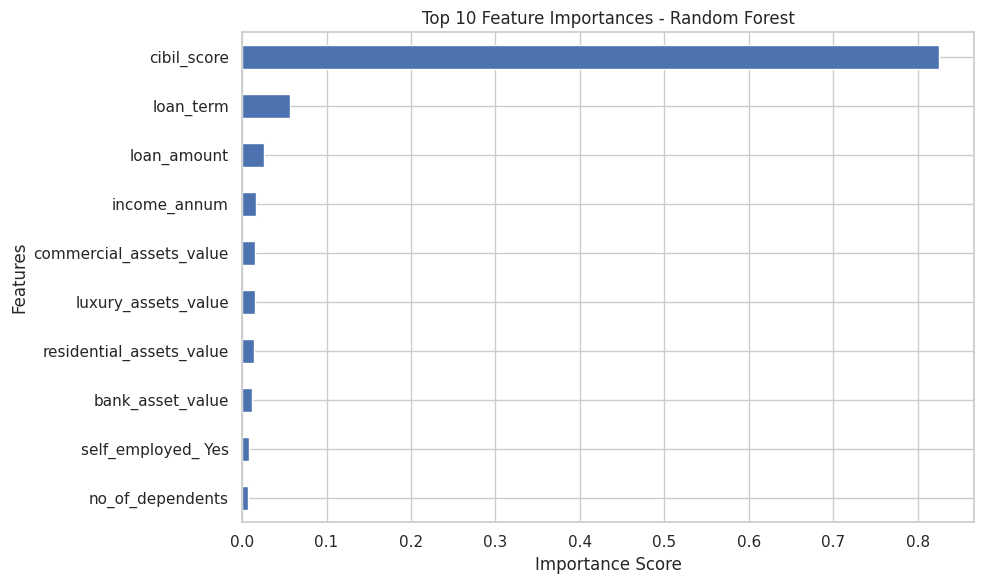

cibil_score                 0.825519
loan_term                   0.056459
loan_amount                 0.026499
income_annum                0.016218
commercial_assets_value     0.015825
luxury_assets_value         0.014871
residential_assets_value    0.014473
bank_asset_value            0.012045
self_employed_ Yes          0.007671
no_of_dependents            0.006426
education_ Not Graduate     0.003993
dtype: float64


In [36]:
# Calculate feature importance
importance = pd.Series(
    model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

# Plot the top 10 features
plt.figure(figsize=(10, 6))
importance.head(10).sort_values().plot(kind="barh")

plt.title("Top 10 Feature Importances - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

print(importance)

## Conclusion

In this project, a Random Forest Classifier was developed to predict loan approval status using the loan approval dataset containing 4,269 records. The dataset was checked for missing values and duplicate records, and categorical features were encoded before model training.

SMOTE was applied to the training data to balance the target classes. The model was evaluated using an 80:20 train-test split and metrics including accuracy, precision, recall, F1-score, and ROC-AUC.

The model achieved an accuracy of **97.89%**, precision of **98.49%**, recall of **98.12%**, F1-score of **98.30%**, and ROC-AUC of **99.86%** on the test set. These results indicate strong performance on the available test data.

However, the unusually high performance should be validated further using leakage checks and additional unseen data. Future improvements could include hyperparameter tuning and testing the model on newer loan applications.